# E3：特徵數量與 C 的交互作用

研究問題：選出較少特徵後，C=0.001 是否仍然合適？

候選：k ∈ {10, 20}，C ∈ {0.001, 0.01, 0.1}。
兩組 C=0.001 重用 E2；四組新設定讀取 E3 輸出。

此 notebook 不重新訓練模型、不上傳 Kaggle，也不根據結果自動擴大搜尋。
所有分數是參與模型選擇的開發驗證結果。


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "configs").is_dir() and (path / "outputs" / "results").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project directory.")

RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "e3_feature_count_c"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = [
    (10, 0.001, "e2_correlation_k_10"),
    (10, 0.01, "e3_correlation_k_10_c_0_01"),
    (10, 0.1, "e3_correlation_k_10_c_0_1"),
    (20, 0.001, "e2_correlation_k_20"),
    (20, 0.01, "e3_correlation_k_20_c_0_01"),
    (20, 0.1, "e3_correlation_k_20_c_0_1"),
]
BASELINE_DIR = RESULTS_DIR / "logistic_c_0_001"
C_VALUES = [0.001, 0.01, 0.1]
print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification


## 1. 載入與一致性檢查

檢查六組結果是否完整、驗證分數是否一致，及實際切分是否與全部特徵基準相同。
同一 k 下，只改 C 不應改變 selector 選出的特徵，因此也核對每折特徵名稱。
此檢查不能取代原始資料雜湊或程式版本紀錄。


In [2]:
required = ["config.json", "summary.json", "fold_scores.csv", "repeat_scores.csv",
            "split_indices.json", "selected_features.json"]
missing = [str(RESULTS_DIR / name / filename) for _, _, name in EXPERIMENTS
           for filename in required if not (RESULTS_DIR / name / filename).is_file()]
missing += [str(BASELINE_DIR / filename) for filename in
            ["config.json", "split_indices.json", "repeat_scores.csv"]
            if not (BASELINE_DIR / filename).is_file()]
if missing:
    raise FileNotFoundError("Missing outputs:\n" + "\n".join(missing))

baseline_config = json.loads((BASELINE_DIR / "config.json").read_text(encoding="utf-8"))
baseline_splits = json.loads((BASELINE_DIR / "split_indices.json").read_text(encoding="utf-8"))
baseline_repeats = pd.read_csv(BASELINE_DIR / "repeat_scores.csv")
if len(baseline_repeats) != 10 or baseline_repeats["split_seed"].duplicated().any():
    raise ValueError("Incomplete or duplicate baseline repetitions.")
if not baseline_repeats["mean_auc"].between(0, 1).all():
    raise ValueError("Invalid baseline AUC.")

frames = []
selection_reference = {}
keys = ["repeat", "split_seed", "fold"]
expected_keys = pd.DataFrame([
    {"repeat": r, "split_seed": r, "fold": fold}
    for r in range(10) for fold in range(5)
])

for k, c, name in EXPERIMENTS:
    directory = RESULTS_DIR / name
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    splits = json.loads((directory / "split_indices.json").read_text(encoding="utf-8"))
    selections = json.loads((directory / "selected_features.json").read_text(encoding="utf-8"))
    folds = pd.read_csv(directory / "fold_scores.csv")
    repeats = pd.read_csv(directory / "repeat_scores.csv")

    if config["feature_selection_k"] != k or config["regularization_c"] != c:
        raise ValueError(f"Unexpected k or C: {name}")
    if config["n_splits"] != 5 or config["split_seeds"] != list(range(10)):
        raise ValueError(f"Unexpected validation scheme: {name}")
    for field in ["model_name", "max_iter", "n_splits", "split_seeds"]:
        if config[field] != baseline_config[field]:
            raise ValueError(f"Baseline mismatch in {field}: {name}")
    if splits["splits"] != baseline_splits["splits"]:
        raise ValueError(f"Different split assignments: {name}")
    if splits["feature_names"] != baseline_splits["feature_names"]:
        raise ValueError(f"Different feature schema: {name}")
    if len(folds) != 50 or folds[keys].duplicated().any():
        raise ValueError(f"Incomplete fold scores: {name}")
    pd.testing.assert_frame_equal(
        folds[keys].sort_values(keys).reset_index(drop=True), expected_keys,
        check_dtype=False,
    )
    if not folds["valid_auc"].between(0, 1).all():
        raise ValueError(f"Invalid fold AUC: {name}")
    if len(repeats) != 10 or repeats[["repeat", "split_seed"]].duplicated().any():
        raise ValueError(f"Incomplete repeat scores: {name}")
    if repeats["split_seed"].duplicated().any() or not repeats["n_folds"].eq(5).all():
        raise ValueError(f"Invalid repeated-validation metadata: {name}")
    if not repeats["mean_auc"].between(0, 1).all():
        raise ValueError(f"Invalid repeat AUC: {name}")
    calculated = folds.groupby(["repeat", "split_seed"], as_index=False)["valid_auc"].mean()
    matched = repeats.merge(calculated, on=["repeat", "split_seed"], validate="one_to_one")
    if len(matched) != 10:
        raise ValueError(f"Repeat keys do not match fold keys: {name}")
    np.testing.assert_allclose(matched["mean_auc"], matched["valid_auc"], atol=1e-12, rtol=0)
    if summary["aggregation"] != "mean_fold_auc_per_repeat":
        raise ValueError(f"Unexpected aggregation: {name}")
    np.testing.assert_allclose(repeats["mean_auc"].mean(), summary["mean_auc"], atol=1e-12, rtol=0)
    np.testing.assert_allclose(repeats["mean_auc"].std(ddof=1), summary["std_auc"], atol=1e-12, rtol=0)

    selected_by_fold = {}
    for record in selections:
        key = (record["repeat"], record["split_seed"], record["fold"])
        names = record["selected_features"]
        if key in selected_by_fold or record["k"] != k or len(names) != k or len(set(names)) != k:
            raise ValueError(f"Invalid feature-selection records: {name}")
        if not set(names).issubset(set(splits["feature_names"])):
            raise ValueError(f"Unknown selected features: {name}")
        selected_by_fold[key] = names
    expected_set = set(expected_keys.itertuples(index=False, name=None))
    if set(selected_by_fold) != expected_set:
        raise ValueError(f"Missing selected-feature records: {name}")
    if k not in selection_reference:
        selection_reference[k] = selected_by_fold
    elif selected_by_fold != selection_reference[k]:
        raise ValueError(f"Selected features changed when only C changed: {name}")

    frames.append(repeats.assign(k=k, C=c, experiment_id=name))

repeat_scores = pd.concat(frames, ignore_index=True)
print("Checks passed: matching splits, scores, and selections within each k.")


Checks passed: matching splits, scores, and selections within each k.


## 2. 六個候選的比較表

三種比較基準：同一 k 的 C=0.001、原本全部特徵基準，以及 E2 首選 k=10/C=0.001。
所有差值均在相同 repeat 和 split seed 下配對。
正值代表候選較高；±1e-12 以內視為數值平手。


In [3]:
summary_table = (
    repeat_scores.groupby(["k", "C"], as_index=False)
    .agg(mean_auc=("mean_auc", "mean"), std_auc=("mean_auc", "std"),
         min_auc=("mean_auc", "min"), max_auc=("mean_auc", "max"),
         n_repeats=("mean_auc", "count"))
)
within_k = repeat_scores.loc[repeat_scores["C"].eq(0.001), ["k", "repeat", "split_seed", "mean_auc"]].rename(
    columns={"mean_auc": "within_k_control_auc"}
)
full_control = baseline_repeats[["repeat", "split_seed", "mean_auc"]].rename(
    columns={"mean_auc": "all_feature_control_auc"}
)
e2_best = repeat_scores.loc[repeat_scores["k"].eq(10) & repeat_scores["C"].eq(0.001),
                            ["repeat", "split_seed", "mean_auc"]].rename(
    columns={"mean_auc": "e2_leading_control_auc"}
)
paired = repeat_scores.merge(within_k, on=["k", "repeat", "split_seed"], validate="many_to_one")
paired = paired.merge(full_control, on=["repeat", "split_seed"], validate="many_to_one")
paired = paired.merge(e2_best, on=["repeat", "split_seed"], validate="many_to_one")
if len(paired) != 60:
    raise ValueError("A comparison lost rows due to unmatched repetition keys.")

for label, control_column in [
    ("within_k", "within_k_control_auc"),
    ("all_features", "all_feature_control_auc"),
    ("e2_leading", "e2_leading_control_auc"),
]:
    difference_column = f"difference_vs_{label}"
    paired[difference_column] = paired["mean_auc"] - paired[control_column]
    aggregate = paired.groupby(["k", "C"], as_index=False).agg(**{
        f"mean_difference_vs_{label}": (difference_column, "mean"),
        f"sd_difference_vs_{label}": (difference_column, "std"),
        f"wins_vs_{label}": (difference_column, lambda x: int((x > 1e-12).sum())),
        f"losses_vs_{label}": (difference_column, lambda x: int((x < -1e-12).sum())),
        f"ties_vs_{label}": (difference_column, lambda x: int((x.abs() <= 1e-12).sum())),
    })
    summary_table = summary_table.merge(aggregate, on=["k", "C"], validate="one_to_one")

summary_table = summary_table.sort_values(["k", "C"]).reset_index(drop=True)
display(summary_table[["k", "C", "mean_auc", "std_auc", "mean_difference_vs_within_k",
                       "wins_vs_within_k", "losses_vs_within_k", "mean_difference_vs_e2_leading",
                       "mean_difference_vs_all_features"]].round(6))
print("Mean development AUC by candidate:")
display(summary_table.pivot(index="k", columns="C", values="mean_auc").round(6))
summary_table.to_csv(FIGURES_DIR / "e3_comparison.csv", index=False)
paired.to_csv(FIGURES_DIR / "e3_paired_repeat_scores.csv", index=False)


,k,C,mean_auc,std_auc,mean_difference_vs_within_k,wins_vs_within_k,losses_vs_within_k,mean_difference_vs_e2_leading,mean_difference_vs_all_features
0,10,0.001,0.808618,0.008244,0.000000,0,0,0.000000,0.014619
1,10,0.010,0.812664,0.007200,0.004046,10,0,0.004046,0.018666
2,10,0.100,0.822982,0.008456,0.014364,10,0,0.014364,0.028983
3,20,0.001,0.798767,0.008428,0.000000,0,0,-0.009851,0.004769
4,20,0.010,0.799816,0.010557,0.001049,5,5,-0.008801,0.005818
5,20,0.100,0.794235,0.013509,-0.004532,3,7,-0.014382,0.000237


Mean development AUC by candidate:


C,0.001,0.010,0.100
k,,,
10,0.808618,0.812664,0.822982
20,0.798767,0.799816,0.794235


## 3. 平均 AUC：C 與特徵數量

誤差棒為十次重複平均分數的樣本標準差，不是信賴區間。
折線只連接已測設定，不是連續 C 值的已知表現。


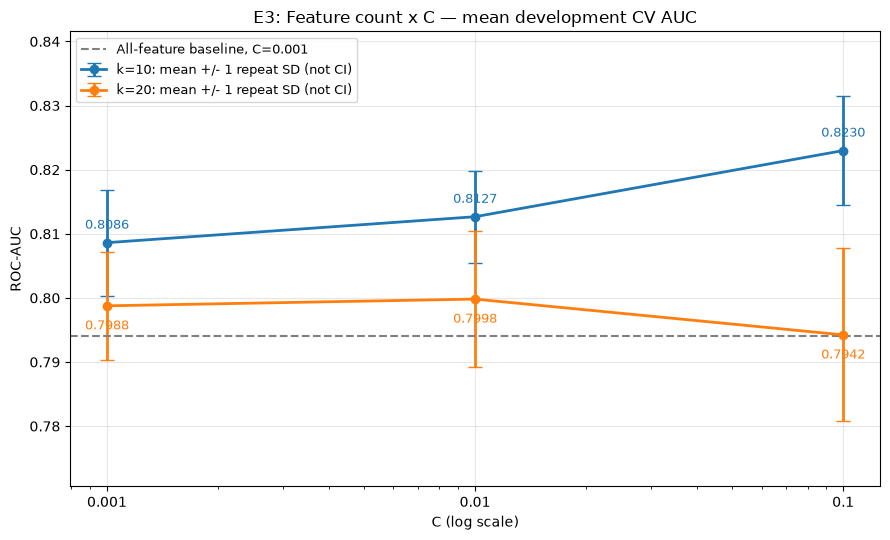

In [4]:
def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES_DIR / f"{name}.pdf", bbox_inches="tight")

fig, ax = plt.subplots(figsize=(9, 5.5))
for k, color in [(10, "tab:blue"), (20, "tab:orange")]:
    group = summary_table.loc[summary_table["k"].eq(k)].sort_values("C")
    ax.errorbar(group["C"], group["mean_auc"], yerr=group["std_auc"],
                fmt="o-", capsize=5, linewidth=2, color=color,
                label=f"k={k}: mean +/- 1 repeat SD (not CI)")
    for row in group.itertuples(index=False):
        ax.annotate(f"{row.mean_auc:.4f}", (row.C, row.mean_auc),
                    xytext=(0, 10 if k == 10 else -17),
                    textcoords="offset points", ha="center", color=color, fontsize=9)
ax.axhline(baseline_repeats["mean_auc"].mean(), color="gray", linestyle="--",
            label="All-feature baseline, C=0.001")
ax.set_xscale("log")
ax.set_xticks(C_VALUES)
ax.set_xticklabels([f"{c:g}" for c in C_VALUES])
ax.set_xlabel("C (log scale)")
ax.set_ylabel("ROC-AUC")
ax.set_title("E3: Feature count x C — mean development CV AUC")
ax.grid(alpha=0.3)
ax.margins(y=0.2)
ax.legend(fontsize=9)
fig.tight_layout()
save_figure(fig, "e3_c_vs_auc")
plt.show()


## 4. 同一切分種子的分數軌跡

每個子圖固定 k，只比較 C；每條彩色線對應同一 split seed。
觀察改變 C 的效益是否在多次切分中方向一致。


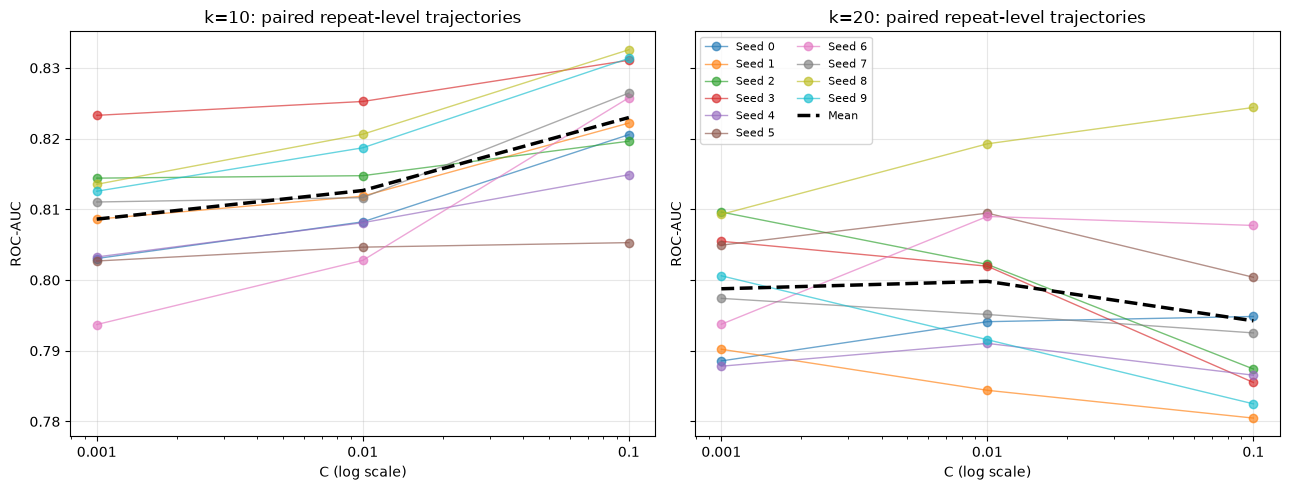

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, k in zip(axes, [10, 20]):
    subset = repeat_scores.loc[repeat_scores["k"].eq(k)]
    for seed, group in subset.groupby("split_seed"):
        group = group.sort_values("C")
        ax.plot(group["C"], group["mean_auc"], "o-", linewidth=1, alpha=0.65, label=f"Seed {seed}")
    average = summary_table.loc[summary_table["k"].eq(k)].sort_values("C")
    ax.plot(average["C"], average["mean_auc"], "k--", linewidth=2.5, label="Mean")
    ax.set_xscale("log")
    ax.set_xticks(C_VALUES)
    ax.set_xticklabels([f"{c:g}" for c in C_VALUES])
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("ROC-AUC")
    ax.set_title(f"k={k}: paired repeat-level trajectories")
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
save_figure(fig, "e3_repeat_trajectories")
plt.show()


## 5. 重新調整 C 的配對改善

比較四個新設定與各自相同 k、C=0.001 的 E2 對照。
正值表示該次切分中調整 C 有改善；黑色菱形是平均差值。
重複切分不是獨立資料集，此圖不是顯著性檢定。


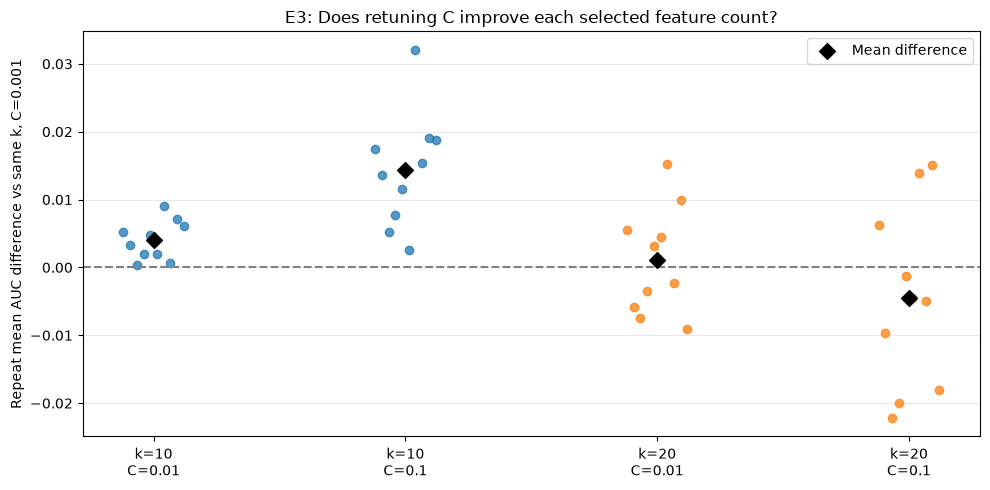

Figures and tables saved to: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/outputs/figures/e3_feature_count_c


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
candidates = [(10, 0.01), (10, 0.1), (20, 0.01), (20, 0.1)]
for position, (k, c) in enumerate(candidates):
    values = paired.loc[paired["k"].eq(k) & paired["C"].eq(c)].sort_values("split_seed")["difference_vs_within_k"].to_numpy()
    offsets = np.linspace(-0.12, 0.12, len(values))
    ax.scatter(position + offsets, values, alpha=0.75, color="tab:blue" if k == 10 else "tab:orange")
    ax.scatter(position, values.mean(), color="black", marker="D", s=65, zorder=3,
               label="Mean difference" if position == 0 else None)
ax.axhline(0, color="gray", linestyle="--")
ax.set_xticks(range(len(candidates)))
ax.set_xticklabels([f"k={k}\nC={c:g}" for k, c in candidates])
ax.set_ylabel("Repeat mean AUC difference vs same k, C=0.001")
ax.set_title("E3: Does retuning C improve each selected feature count?")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
save_figure(fig, "e3_paired_differences")
plt.show()
print(f"Figures and tables saved to: {FIGURES_DIR}")


## 6. 結論紀錄（執行後填寫）

- k=10 之內，三個 C 的差異與一致性：待填。
- k=20 之內，三個 C 的差異與一致性：待填。
- 本輪最高平均開發分數的候選：待填。
- 相對 E2 首選 k=10/C=0.001 的平均配對差值及改善次數：待填。
- 相對全部特徵基準的平均配對差值及改善次數：待填。
- 決策及理由，包括差異是否小到不足以支持更換設定：待填。

本輪由 E2 結果決定 k，是適應式開發的一部分，不是獨立確認。
不能只因平均分數最高就宣稱真實泛化最佳；亦不以誤差棒是否重疊代替配對分析。
完成四個新設定後先停止，保留結果，再決定下一項實驗。
